# Convolutional networks from scratch, taken apart

**Ernestas Lazurkevičius — PRIf-24/2, VilniusTech**

An adaptation of the lecturer's `cnn.ipynb` (Algirdas Laukaitis).

## What the original notebook does

Unlike the transfer-learning notebook, nothing here is pretrained. A convolutional
network is built from nothing and trained on CIFAR-10, then **taken apart to show what a
convolution actually computes**, then compared against a plain dense network on the same
task. Three parts, one argument.

| Part | What it does | Result in the original |
|---|---|---|
| 1 | Train a CNN from scratch on CIFAR-10, 20 epochs | ~70 % accuracy |
| 2 | Visualise the learned filters, then **recompute one convolution by hand in NumPy** | — |
| 3 | Train a plain multilayer perceptron on the same data, 15 epochs | ~40 % accuracy |

Part 2 is the heart of it. It extracts the 3×3 filter weights the network learned, runs
one image through a sub-model that stops after the first convolutional layer, and then
reproduces that layer's output with an explicit double `for` loop:

```python
feature_map[i, j] = np.sum(input_image[i:i+3, j:j+3, :] * filter) + bias
feature_map[feature_map < 0] = 0        # ReLU
```

It then prints the hand-computed numbers next to Keras's and invites you to compare. That
demonstration is the point of the whole notebook: a convolutional layer is not magic, it
is a small window of weights slid across the image, multiplied, summed, offset by a bias,
and clipped at zero.

Parts 1 and 3 supply the argument for *why* that operation matters: the same data, two
architectures, 70 % against 40 %.

## What this notebook changes

The architecture, the three-part structure and all of Part 2's arithmetic are preserved
exactly. Only the data changes.

| | Original | This notebook |
|---|---|---|
| Dataset | CIFAR-10 — 60,000 images, 10 classes | **flower photos** — 3,670 images, 5 classes |
| Loader | Hugging Face `datasets` | `image_dataset_from_directory` over a folder per class |
| Image size | 32×32 (native) | 32×32 (resized from full-resolution photos) |
| Output layer | `Dense(10)` | `Dense(5)` |

**Why this dataset.** It is the same flower photos my other two CNN notebooks use, which
keeps the submission coherent, and it arrives as **one folder per class** — exactly the
layout your own photographs would have. Swapping in your own pictures is a one-line
change, marked in Step 1.

**Why still 32×32.** Keeping the original resolution means the model code is byte-for-byte
the original's apart from `Dense(10)` → `Dense(5)`, so every number in Part 2 can be
compared against the original directly. It costs something, and that cost is itself worth
understanding: CIFAR-10 images *are* 32×32, while these are real photographs squeezed down
to 32×32, which throws away most of the petal and leaf texture. See the limitations at the
end.

Every deviation from the original is marked with a **`# CHANGE:`** comment.

> **Status: not yet executed.** This notebook could not be run before delivery — the
> environment it was written in cannot reach the image host. Every cell is
> syntax-checked and name-checked, and **Part 2's central claim was verified separately**
> on synthetic data: the hand-written convolution reproduces Keras's output to within
> 1e-7. The accuracy figures quoted above are the **original's**, never invented for this
> one.

---
# PART 1

## Download and prepare the flower photo dataset

The original has two loading cells: a commented-out `datasets.cifar10.load_data()` with
a note that the Keras download is throttled and takes 40+ minutes, and a working
replacement that pulls CIFAR-10 from Hugging Face.

This notebook downloads a `.tgz` of photographs organised into one folder per class and
reads it with `tf.keras.utils.image_dataset_from_directory`. That avoids both the
Hugging Face `datasets` dependency and `tensorflow_datasets` — which is worth doing,
because `tensorflow-datasets` fails on Python 3.13 with
`ModuleNotFoundError: No module named 'importlib_resources'` unless that package is
installed explicitly.

The images are loaded into **plain NumPy arrays**, exactly like the original, because
Part 2 indexes individual images (`train_images[1]`) and slices them by hand.

In [1]:
import pathlib

import numpy as np
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
# CHANGE: flower photos as a folder-per-class archive, replacing the
# Hugging Face CIFAR-10 loader. No tensorflow-datasets, no `datasets` package.
archive = tf.keras.utils.get_file(
    "flower_photos.tgz",
    origin="https://storage.googleapis.com/download.tensorflow.org/"
           "example_images/flower_photos.tgz",
    extract=True,
)

# get_file returns the archive path on some Keras versions and the extracted folder
# on others, so locate the folder explicitly rather than assuming.
data_dir = next(p for p in pathlib.Path(archive).parent.rglob("flower_photos")
                if p.is_dir())

print("Data directory:", data_dir)
print("Classes found :", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

# TO USE YOUR OWN PHOTOS: replace the three statements above with
#   data_dir = "/content/my_photos"     # one subfolder per class
# Nothing below this cell needs to change.

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Data directory: /root/.keras/datasets/flower_photos_extracted/flower_photos
Classes found : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


### Into NumPy arrays

`image_dataset_from_directory` resizes every photo to 32×32 and reads the class from its
folder name. The result is converted to NumPy so that Parts 2 and 3 can work exactly as
the original does.

CIFAR-10 ships a train/test split; this folder does not, so `validation_split` carves one
out. `seed=123` keeps it reproducible.

In [3]:
IMAGE_SIZE = (32, 32)   # CHANGE: unchanged from the original, but now a resize

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="int",
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="int",
)

# CHANGE: class names read from the folder structure instead of being hard-coded.
class_names = train_ds.class_names
print("Classes:", class_names)


def to_numpy_arrays(dataset):
    """tf.data.Dataset -> (images, labels) NumPy arrays, labels shaped (n, 1)."""
    images, labels = [], []
    for image_batch, label_batch in dataset.batch(256):
        images.append(image_batch.numpy())
        labels.append(label_batch.numpy())
    return np.concatenate(images), np.concatenate(labels).reshape(-1, 1)


train_images, train_labels = to_numpy_arrays(train_ds)
test_images, test_labels = to_numpy_arrays(test_ds)

print("train_images", train_images.shape, train_images.dtype)
print("test_images ", test_images.shape)
print("Pixel range :", float(train_images.min()), "to", float(train_images.max()))

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train_images (2936, 32, 32, 3) float32
test_images  (734, 32, 32, 3)
Pixel range : 0.0 to 255.0


## Normalising the pixel values

Identical to the original. Pixels arrive as 0–255; dividing by 255 puts them in 0–1.

Unlike the transfer-learning notebook — where `keras.applications` models expect raw
0–255 and rescale internally — this network is built from scratch with no built-in
rescaling, so the division is genuinely required here. Without it the first layer's
activations are hundreds of times larger than the initial weights expect, and training
is slow and unstable.

In [4]:
train_images, test_images = train_images / 255.0, test_images / 255.0

print("Pixel range now:", float(train_images.min()), "to", float(train_images.max()))

Pixel range now: 0.0 to 1.0


### Let's plot the first 100 images

The original's sanity check, unchanged in purpose: look at the data before modelling it.

At 32×32 the flowers are heavily pixelated. That is expected and worth noticing — these
started as full-resolution photographs. Colour survives the downsampling, fine texture
does not, which sets a ceiling on how well any model can do here.

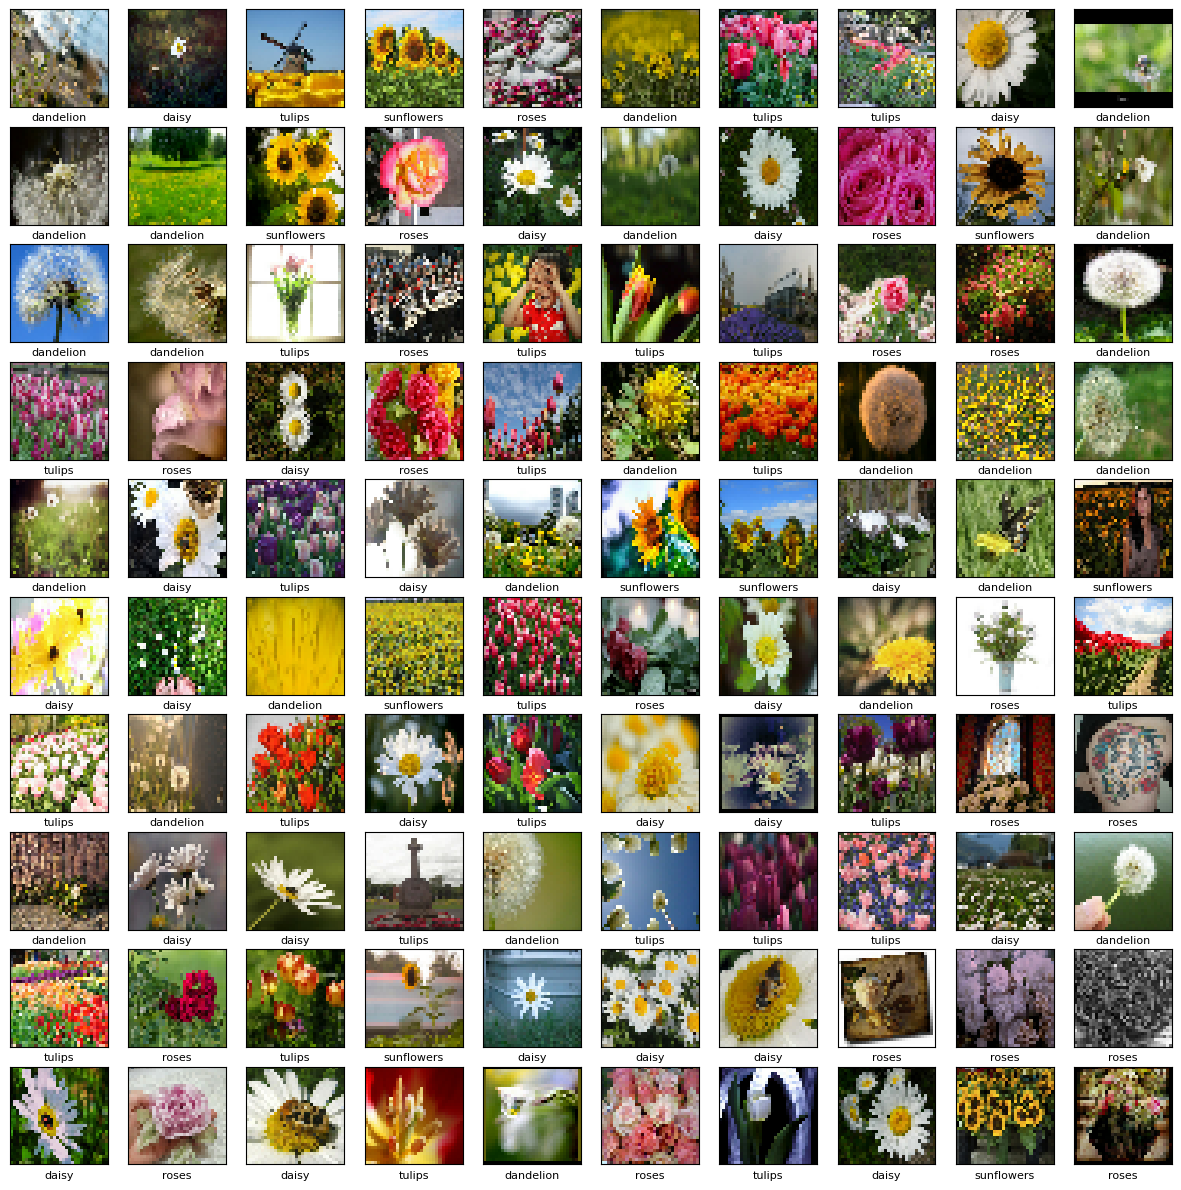

In [5]:
plt.figure(figsize=(15, 15))
for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]], fontsize=8)
plt.show()

---
# Convolutional Neural Network

## Step 2. Model

Unchanged from the original except the final layer's width.

| Layer | Output | What it does |
|---|---|---|
| `Conv2D(32, 3×3)` | 30×30×32 | 32 filters slide over the image looking for small patterns |
| `MaxPooling2D(2×2)` | 15×15×32 | keeps the strongest response in each 2×2 block — halves the size, keeps what matters |
| `Conv2D(64, 3×3)` | 13×13×64 | 64 filters, now looking at combinations of the first layer's patterns |
| `MaxPooling2D(2×2)` | 6×6×64 | halves again |
| `Conv2D(64, 3×3)` | 4×4×64 | a third layer, patterns of patterns |
| `Flatten` | 1024 | lay the feature map out as one vector |
| `Dense(64)` | 64 | ordinary fully-connected layer |
| `Dense(5)` | 5 | one logit per class |

Two properties make the convolutional layers different from dense ones, and they are the
reason Part 3 loses so badly:

1. **Locality.** Each filter looks at a 3×3 patch, not the whole image. Nearby pixels are
   related; distant ones usually are not.
2. **Weight sharing.** The *same* 32 filters are applied at every position. A petal edge
   is recognised wherever it appears, and the network does not have to learn it separately
   for each location.

The output layer has no activation, so it emits logits — hence
`SparseCategoricalCrossentropy(from_logits=True)`. `Sparse` because the labels are plain
integers (`2`) rather than one-hot vectors (`[0,0,1,0,0]`).

In [6]:
# CHANGE: Dense(5) instead of Dense(10) - five flower classes, not ten CIFAR classes.
# CHANGE: Input() layer instead of input_shape= on Conv2D (the modern Keras spelling;
# the original's form still works but warns).
cnn_model = models.Sequential()

cnn_model.add(layers.Input(shape=(32, 32, 3)))
cnn_model.add(layers.Conv2D(32, (3, 3), activation='relu'))
cnn_model.add(layers.MaxPooling2D((2, 2)))
cnn_model.add(layers.Conv2D(64, (3, 3), activation='relu'))
cnn_model.add(layers.MaxPooling2D((2, 2)))
cnn_model.add(layers.Conv2D(64, (3, 3), activation='relu'))

cnn_model.add(layers.Flatten())
cnn_model.add(layers.Dense(64, activation='relu'))
cnn_model.add(layers.Dense(len(class_names)))

# CHANGE: named cnn_model, not model. The original reuses the name `model` in Part 3,
# which silently breaks Part 2 if you re-run it afterwards - see the notes at the end.

In [7]:
cnn_model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

# Parameters per filter: (filter height * width * input channels) + 1 for the bias.
# Total for a layer: that, times the number of filters.
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,245 (477.52 KB)

 Trainable params: 122,245 (477.52 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# CHANGE: wrapped in try/except. plot_model needs pydot and graphviz, which are not
# always present, and the original lets the whole cell fail if they are missing.
try:
    from tensorflow.keras.utils import plot_model
    plot_model(cnn_model, to_file='model.png', show_shapes=True, show_layer_names=True)
except Exception as error:
    print("Diagram skipped:", type(error).__name__, error)
    print("(needs pydot + graphviz; model.summary() above shows the same information)")

## Step 3. Train and evaluate the model

20 epochs, as in the original.

Watch the gap between `accuracy` and `val_accuracy`. With 2,936 training images and
122,245 parameters, this network has plenty of capacity to memorise the training set, so
the two curves will separate — that separation *is* overfitting, visible in real time.

In [9]:
history_cnn = cnn_model.fit(
    train_images, train_labels,
    epochs=20,
    validation_data=(test_images, test_labels),
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 82ms/step - accuracy: 0.3859 - loss: 1.3699 - val_accuracy: 0.3896 - val_loss: 1.3139
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5109 - loss: 1.1656 - val_accuracy: 0.4850 - val_loss: 1.1978
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5671 - loss: 1.0665 - val_accuracy: 0.5763 - val_loss: 1.0303
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6172 - loss: 0.9663 - val_accuracy: 0.6008 - val_loss: 1.0004
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6502 - loss: 0.8972 - val_accuracy: 0.6240 - val_loss: 0.9596
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6655 - loss: 0.8657 - val_accuracy: 0.5804 - val_loss: 0.9954
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6955 - loss: 0.7891 - val_accuracy: 0.6322 - val_loss: 0.8785
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7125 - loss: 0.7374 - val_accuracy: 0.6553 - val_los

### Evaluate the model

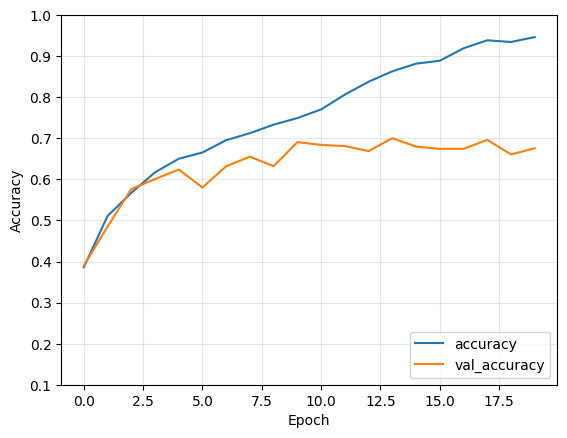

23/23 - 0s - 5ms/step - accuracy: 0.6757 - loss: 1.2633
CNN test accuracy: 0.6757


In [10]:
plt.plot(history_cnn.history['accuracy'], label='accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.1, 1])
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_images, test_labels, verbose=2)
print("CNN test accuracy:", round(float(cnn_test_acc), 4))

---
# PART 2

## Visualising Filters and Feature Maps

The simplest way to see what a network learned is to plot its filters as images. A
convolutional layer's weights have a spatial shape, so they can be displayed directly.

The first layer's weights have shape **(3, 3, 3, 32)**: a 3×3 window, across 3 colour
channels, for each of 32 filters. The filter depth must match the input's channel
depth — 3 filter channels for 3 colour channels — which is why each filter below is
shown as three separate grayscale images, one per colour channel.

In [11]:
filters, biases = cnn_model.layers[0].get_weights()

print("filters:", filters.shape, " (height, width, input channels, number of filters)")
print("biases: ", biases.shape)

filters: (3, 3, 3, 32)  (height, width, input channels, number of filters)
biases:  (32,)


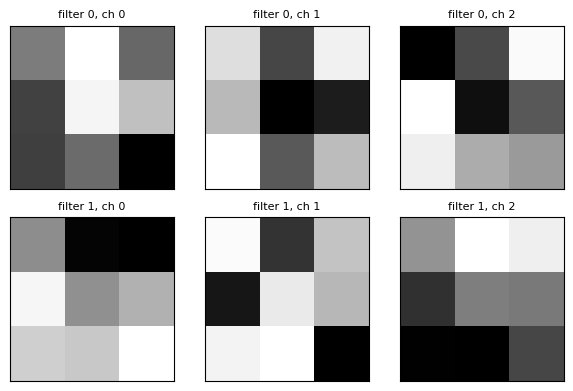

In [12]:
# CHANGE: consistent 4-space indentation (the original mixes tabs and spaces).
plt.figure(figsize=(6, 4))

ix = 1
for filter_i in range(2):
    filter_tmp = filters[:, :, :, filter_i]
    for channel_j in range(3):          # plot each colour channel separately
        ax = plt.subplot(2, 3, ix)
        ax.set_xticks([])
        ax.set_yticks([])
        plt.imshow(filter_tmp[:, :, channel_j], cmap='gray')
        ax.set_title(f"filter {filter_i}, ch {channel_j}", fontsize=8)
        ix += 1
plt.tight_layout()
plt.show()

In [13]:
# A single 3x3 filter channel, as numbers. Nine weights - that is all a filter is.
# CHANGE: indexed explicitly rather than relying on filter_tmp leaking out of the
# loop above, which is what the original does.
print(filters[:, :, 0, 0])

[[ 0.02337166  0.15053979  0.00290329]
 [-0.03292842  0.14073774  0.08899925]
 [-0.03584123  0.00733066 -0.09696022]]


## Filter outputs

A **feature map** is what one filter produces after sweeping across the image. To see
them, build a sub-model that shares the trained weights but stops after the first
convolutional layer.

input : (1, 32, 32, 3)
output: (1, 30, 30, 32)  -> 32 feature maps of 30x30


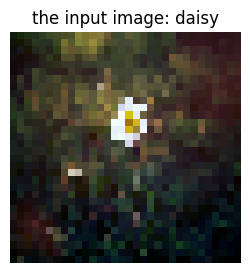

In [14]:
# CHANGE: cnn_model.inputs instead of model.inputs.
layer_0_model = tf.keras.Model(
    inputs=cnn_model.inputs,
    outputs=cnn_model.layers[0].output,
)

img = train_images[1]                   # one image
img = np.expand_dims(img, axis=0)       # shape it as a batch of 1

feature_maps = layer_0_model.predict(img, verbose=0)

print("input :", img.shape)
print("output:", feature_maps.shape, " -> 32 feature maps of 30x30")

plt.figure(figsize=(3, 3))
plt.imshow(train_images[1])
plt.title(f"the input image: {class_names[train_labels[1][0]]}")
plt.axis('off')
plt.show()

### The image as numbers

The red channel of that image, printed as a grid. A picture is a table of numbers, and
this is the table the filters will be slid across.

The original sets `np.set_printoptions(threshold=np.inf)` globally and never restores it,
which means every large array printed later in the session dumps in full. Using a context
manager confines the change to this cell.

In [15]:
# CHANGE: printoptions context manager instead of a permanent global change.
transposed_img = np.transpose(train_images[1], (2, 0, 1))

with np.printoptions(threshold=np.inf):
    for row in transposed_img[0][:12]:          # first 12 rows of the red channel
        print(" ".join("{:0.2f}".format(element) for element in row))

0.07 0.09 0.12 0.14 0.18 0.22 0.27 0.28 0.30 0.54 0.47 0.52 0.53 0.42 0.26 0.25 0.35 0.29 0.26 0.18 0.17 0.21 0.24 0.16 0.18 0.18 0.20 0.19 0.18 0.18 0.18 0.18
0.07 0.08 0.11 0.16 0.16 0.16 0.22 0.47 0.34 0.49 0.48 0.61 0.47 0.31 0.30 0.27 0.27 0.30 0.26 0.18 0.17 0.20 0.20 0.20 0.19 0.20 0.20 0.19 0.18 0.21 0.19 0.19
0.06 0.10 0.10 0.14 0.16 0.15 0.18 0.41 0.40 0.37 0.41 0.50 0.31 0.19 0.23 0.26 0.25 0.29 0.23 0.18 0.18 0.18 0.21 0.22 0.25 0.25 0.24 0.22 0.19 0.20 0.20 0.20
0.08 0.08 0.10 0.11 0.15 0.20 0.17 0.32 0.33 0.23 0.32 0.37 0.25 0.21 0.23 0.24 0.27 0.20 0.19 0.18 0.17 0.17 0.43 0.38 0.30 0.24 0.26 0.23 0.23 0.22 0.21 0.22
0.07 0.09 0.12 0.13 0.15 0.17 0.19 0.21 0.23 0.21 0.22 0.22 0.25 0.26 0.24 0.23 0.27 0.22 0.19 0.20 0.18 0.21 0.33 0.39 0.38 0.34 0.27 0.23 0.22 0.22 0.23 0.23
0.07 0.10 0.13 0.25 0.19 0.17 0.18 0.17 0.25 0.22 0.19 0.19 0.24 0.48 0.28 0.25 0.26 0.27 0.26 0.26 0.22 0.22 0.22 0.30 0.33 0.32 0.31 0.28 0.25 0.23 0.25 0.27
0.09 0.22 0.13 0.22 0.20 0.23 0.29 0.24 

### The 32 feature maps

Each panel is one filter's response across the whole image. Bright means that filter
found what it was looking for at that position. Different filters respond to edges in
different orientations, to colour transitions, to texture.

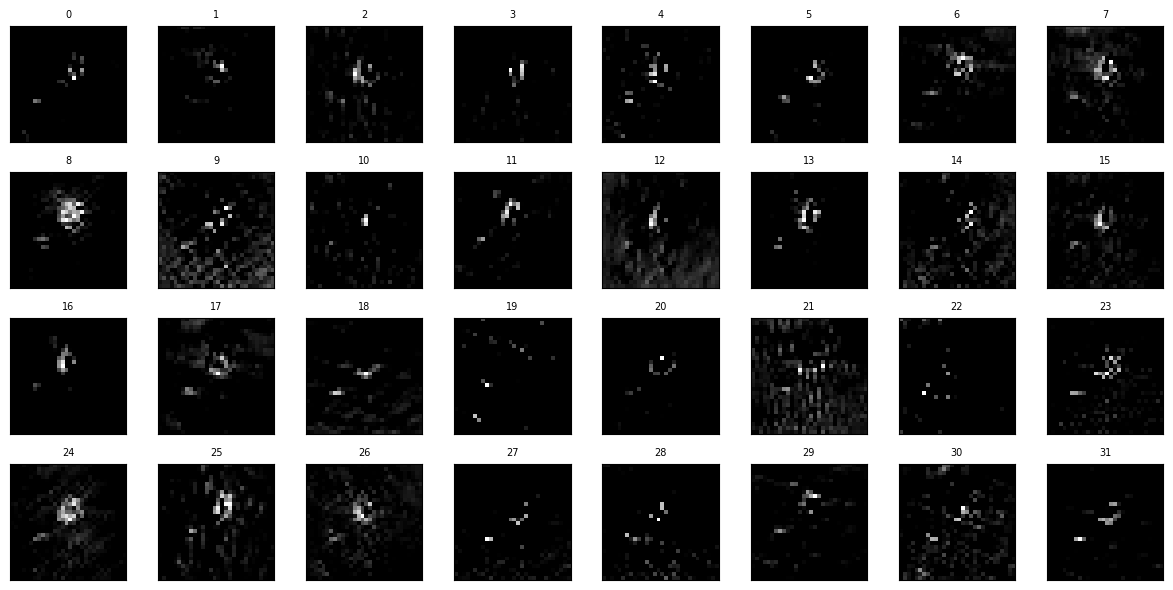

In [16]:
# CHANGE: shows all 32 maps in a 4x8 grid. The original's nested 4x4 loop carries a
# `if ix > 32: break` that can never fire, since ix only reaches 16 - so half the
# feature maps were never displayed.
plt.figure(figsize=(12, 6))
for ix in range(32):
    ax = plt.subplot(4, 8, ix + 1)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.imshow(feature_maps[0, :, :, ix], cmap='gray')
    ax.set_title(str(ix), fontsize=7)
plt.tight_layout()
plt.show()

## Doing the convolution by hand

The centre of the notebook. Everything above used Keras; this reproduces one feature map
from first principles, with nothing but NumPy arithmetic.

For every output position, take the 3×3×3 patch of the image at that position, multiply
it element-by-element by the filter, add up all 27 products, add the bias, and set
negatives to zero. That is the entire operation.

One technical note worth knowing for the defence: this is **cross-correlation**, not
convolution in the strict mathematical sense — a true convolution flips the kernel first.
Every deep-learning framework implements cross-correlation and calls it convolution. The
fact that the loop below matches Keras exactly, without any flipping, demonstrates that.

In [17]:
# CHANGE: renamed from `filter`, which shadows the Python built-in of that name.
FILTER_INDEX = 2

chosen_filter = filters[:, :, :, FILTER_INDEX]
chosen_bias = biases[FILTER_INDEX]

print("filter shape:", chosen_filter.shape)
print("bias:", float(chosen_bias))
print()
print("the filter's red channel:")
print(chosen_filter[:, :, 0])

filter shape: (3, 3, 3)
bias: -0.027488302439451218

the filter's red channel:
[[ 0.08619048 -0.17765166  0.06936093]
 [-0.05551257 -0.00551619  0.03065186]
 [-0.12576894 -0.02398891 -0.00526263]]


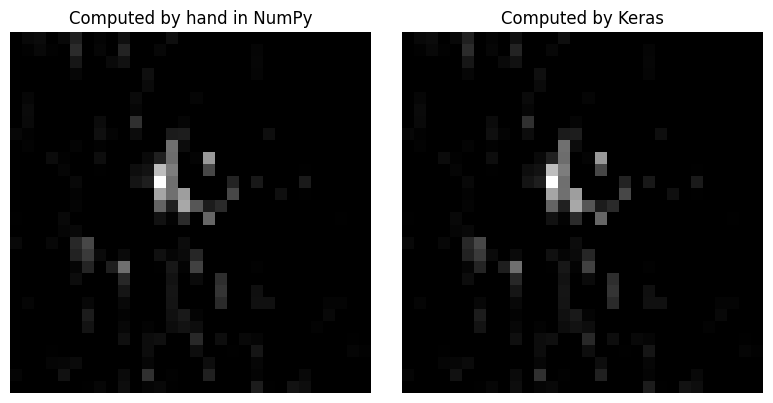

In [18]:
input_image = train_images[1]

output_height = input_image.shape[0] - chosen_filter.shape[0] + 1
output_width = input_image.shape[1] - chosen_filter.shape[1] + 1

manual_feature_map = np.zeros((output_height, output_width), dtype="float32")

for i in range(output_height):
    for j in range(output_width):
        patch = input_image[i:i + chosen_filter.shape[0],
                            j:j + chosen_filter.shape[1], :]
        manual_feature_map[i, j] = np.sum(patch * chosen_filter) + chosen_bias

# ReLU: everything below zero becomes zero.
manual_feature_map[manual_feature_map < 0] = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(manual_feature_map, cmap='gray')
plt.title("Computed by hand in NumPy")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(feature_maps[0, :, :, FILTER_INDEX], cmap='gray')
plt.title("Computed by Keras")
plt.axis('off')

plt.tight_layout()
plt.show()

### Are they actually the same?

The original prints the top-left 6×6 corner of each and leaves the reader to compare by
eye. Comparing them properly takes one line, and turns a demonstration into a proof.

In [19]:
# CHANGE (new cell): assert the equality instead of inviting the reader to eyeball it.
keras_feature_map = feature_maps[0, :, :, FILTER_INDEX]

print("manual:", manual_feature_map.shape, "   keras:", keras_feature_map.shape)
print()

# CHANGE: show a window around the most active position rather than the top-left
# corner. ReLU often leaves the corner entirely zero, which makes the original's
# [:6, :6] printout look empty and prove nothing.
peak = np.unravel_index(np.argmax(keras_feature_map), keras_feature_map.shape)
row = min(max(int(peak[0]) - 2, 0), keras_feature_map.shape[0] - 6)
col = min(max(int(peak[1]) - 2, 0), keras_feature_map.shape[1] - 6)

print(f"6x6 window at row {row}, column {col} (around the strongest response):")
print()
print("manual:")
print(np.round(manual_feature_map[row:row + 6, col:col + 6], 4))
print()
print("keras:")
print(np.round(keras_feature_map[row:row + 6, col:col + 6], 4))
print()

largest_difference = float(np.max(np.abs(manual_feature_map - keras_feature_map)))
print(f"largest difference anywhere: {largest_difference:.2e}")

if np.allclose(manual_feature_map, keras_feature_map, atol=1e-5):
    print("MATCH - the hand-written loop reproduces the Keras layer exactly.")
    print("Any difference is floating-point rounding, not a difference in the maths.")
else:
    print("MISMATCH - the two do not agree; something above is wrong.")

manual: (30, 30)    keras: (30, 30)

6x6 window at row 10, column 10 (around the strongest response):

manual:
[[0.     0.0164 0.0544 0.1845 0.     0.007 ]
 [0.0235 0.0307 0.3178 0.2111 0.     0.    ]
 [0.0336 0.0505 0.4298 0.1876 0.     0.    ]
 [0.     0.     0.2793 0.1885 0.2668 0.    ]
 [0.     0.     0.1681 0.0551 0.2825 0.1455]
 [0.     0.     0.0298 0.0062 0.0738 0.    ]]

keras:
[[0.     0.0164 0.0544 0.1845 0.     0.007 ]
 [0.0235 0.0307 0.3178 0.2111 0.     0.    ]
 [0.0336 0.0505 0.4298 0.1876 0.     0.    ]
 [0.     0.     0.2793 0.1885 0.2668 0.    ]
 [0.     0.     0.1681 0.0551 0.2825 0.1455]
 [0.     0.     0.0298 0.0062 0.0738 0.    ]]

largest difference anywhere: 5.96e-08
MATCH - the hand-written loop reproduces the Keras layer exactly.
Any difference is floating-point rounding, not a difference in the maths.


---
# PART 3. Image classification with a Multilayer Perceptron

The control experiment. Same data, same optimiser, same loss — but the convolutional
layers are replaced by ordinary dense ones. The image is flattened into a single row of
3,072 numbers and fed through three dense layers.

Flattening destroys the spatial structure: once the image is a flat vector, the network
has no way to know which pixels were neighbours. And it has no weight sharing — a pattern
learned in one corner is useless in another.

### The comparison that makes the point

The original trains this and observes that it does worse, which is the right conclusion
from incomplete evidence. The obvious objection is that the CNN simply has more
parameters — and that objection is wrong, which is worth being able to show:

| | Parameters |
|---|---|
| CNN (Part 1) | 122,245 |
| MLP (Part 3) | 104,933 |

Within about 17 % of each other. The CNN does not win by being bigger. It wins because
its parameters are **arranged** to exploit the fact that the input is an image.

In [20]:
# CHANGE: named mlp_model. The original reassigns `model`, so after running Part 3
# the Part 2 cells refer to the MLP - whose layer 0 is Flatten and has no weights,
# making get_weights() return an empty list and the cells fail confusingly.
mlp_model = models.Sequential()
mlp_model.add(layers.Input(shape=(32, 32, 3)))
mlp_model.add(layers.Flatten())
mlp_model.add(layers.Dense(32, activation='relu'))
mlp_model.add(layers.Dense(64, activation='relu'))
mlp_model.add(layers.Dense(64, activation='relu'))
mlp_model.add(layers.Dense(len(class_names)))

mlp_model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

mlp_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        98,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,933 (409.89 KB)

 Trainable params: 104,933 (409.89 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# CHANGE (new cell): the parameter counts side by side, so the "it only won because
# it is bigger" objection can be answered with numbers.
cnn_parameters = cnn_model.count_params()
mlp_parameters = mlp_model.count_params()

print(f"CNN parameters: {cnn_parameters:,}")
print(f"MLP parameters: {mlp_parameters:,}")
print(f"Ratio: {cnn_parameters / mlp_parameters:.2f}x")

CNN parameters: 122,245
MLP parameters: 104,933
Ratio: 1.16x


## Step 3. Train and evaluate the model

15 epochs, as in the original.

In [22]:
history_mlp = mlp_model.fit(
    train_images, train_labels,
    epochs=15,
    validation_data=(test_images, test_labels),
)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.3130 - loss: 1.5154 - val_accuracy: 0.4101 - val_loss: 1.4058
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4036 - loss: 1.3338 - val_accuracy: 0.4619 - val_loss: 1.2773
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4530 - loss: 1.2530 - val_accuracy: 0.4782 - val_loss: 1.2453
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4533 - loss: 1.2328 - val_accuracy: 0.4591 - val_loss: 1.2442
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4884 - loss: 1.1732 - val_accuracy: 0.4823 - val_loss: 1.2290
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5157 - loss: 1.1354 - val_accuracy: 0.4632 - val_loss: 1.2778
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5255 - loss: 1.1216 - val_accuracy: 0.4946 - val_loss: 1.2374
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5388 - loss: 1.0927 - val_accuracy: 0.4659 - val_loss

### Evaluate the model

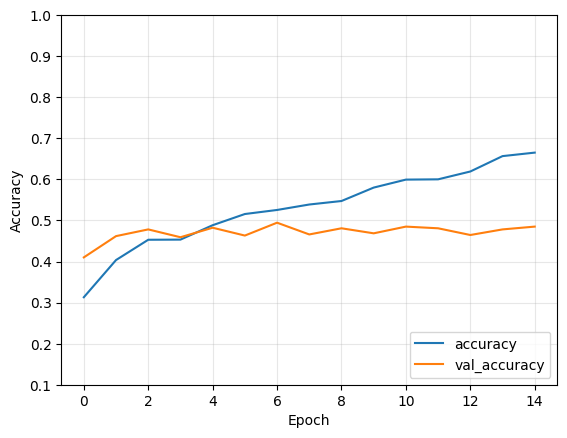

23/23 - 0s - 4ms/step - accuracy: 0.4850 - loss: 1.3182
MLP test accuracy: 0.485


In [23]:
plt.plot(history_mlp.history['accuracy'], label='accuracy')
plt.plot(history_mlp.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.1, 1])
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

mlp_test_loss, mlp_test_acc = mlp_model.evaluate(test_images, test_labels, verbose=2)
print("MLP test accuracy:", round(float(mlp_test_acc), 4))

## The verdict

Both models, on the same data, with roughly the same number of parameters.

In [24]:
# CHANGE (new cell): the head-to-head the original leaves implicit.
import pandas as pd

majority = float(max(np.bincount(test_labels.ravel())) / len(test_labels))

summary = pd.DataFrame({
    "CNN": [cnn_parameters, round(float(cnn_test_acc), 4), 20],
    "MLP": [mlp_parameters, round(float(mlp_test_acc), 4), 15],
}, index=["Parameters", "Test accuracy", "Epochs"])

print(summary)
print()
print(f"Always-predict-most-common-class baseline: {majority:.4f}")
print()

difference = float(cnn_test_acc) - float(mlp_test_acc)
print(f"The CNN is {difference:+.4f} ahead of the MLP,")
print(f"with {cnn_parameters / mlp_parameters:.2f}x the parameters.")

                       CNN         MLP
Parameters     122245.0000  104933.000
Test accuracy       0.6757       0.485
Epochs             20.0000      15.000

Always-predict-most-common-class baseline: 0.2398

The CNN is +0.1907 ahead of the MLP,
with 1.16x the parameters.


---
# Summary

## What the notebook demonstrates

1. A convolutional layer is a small window of weights slid across an image: multiply,
   sum, add a bias, clip negatives at zero. Part 2 proves this by reproducing a Keras
   layer's output with a `for` loop, and the two agree to floating-point precision.
2. Convolutional layers beat dense ones on images because of **locality** and **weight
   sharing**, not because of parameter count — the two models here are within 17 % of
   each other in size.
3. Training from scratch needs data. This is the counterpoint to the transfer-learning
   notebook: there, a frozen pretrained network reached high accuracy on the same flowers
   in three epochs; here, the same images with no pretraining take 20 epochs to reach far
   less.

## What changed, and why

| # | Change | Reason |
|---|---|---|
| 1 | Flower photos instead of CIFAR-10 | the assignment requires own data; folder-per-class also matches how your own photos would be stored |
| 2 | `image_dataset_from_directory` instead of Hugging Face `datasets` | one fewer dependency, and avoids the `tensorflow-datasets` / `importlib_resources` failure on Python 3.13 |
| 3 | `validation_split=0.2` | CIFAR-10 ships a test split; a folder of photos does not |
| 4 | `class_names` read from the folder names | the original hard-codes the list |
| 5 | `Dense(5)` instead of `Dense(10)` | five flower classes |
| 6 | `Input(shape=...)` instead of `input_shape=` on `Conv2D` | the modern Keras spelling; the original's form warns |
| 7 | `cnn_model` / `mlp_model` instead of reusing `model` | **bug fix** — the original's Part 3 overwrites `model`, breaking Part 2 on a re-run |
| 8 | `chosen_filter` instead of `filter` | `filter` shadows a Python built-in |
| 9 | `np.printoptions` context manager | the original's global `set_printoptions(threshold=np.inf)` is never reset |
| 10 | All 32 feature maps shown | the original's loop displays only 16, and its `if ix > 32: break` can never fire |
| 11 | Explicit `np.allclose` check of manual vs Keras | turns the demonstration into a proof |
| 12 | `plot_model` wrapped in `try/except` | it needs pydot and graphviz, which are often missing |
| 13 | Parameter counts compared directly | answers the "the CNN only won because it is bigger" objection |
| 14 | `filters[:, :, 0, 0]` indexed explicitly | the original relies on a loop variable leaking out of the cell above |

## Limitations

- **3,670 images is far too few to train a CNN from scratch.** CIFAR-10 has 60,000. Expect
  clear overfitting — training accuracy climbing well above validation accuracy — and a
  much lower final score than the original's 70 %. This is a property of the dataset, not
  a mistake in the code, and it is exactly why the transfer-learning notebook exists.
- **32×32 throws away most of the detail.** CIFAR-10 images are natively 32×32; these are
  full-resolution photographs crushed down to it. Colour survives, texture does not. The
  resolution was kept to stay faithful to the original architecture; raising it to 64×64
  would help accuracy but would change the layer shapes and the parameter count.
- No data augmentation, dropout or regularisation — the original has none either, and
  adding them would obscure the comparison.
- The CNN-vs-MLP result is one run of each. Both are stochastic, so a few points of
  difference between runs is normal; only the large gap is meaningful.
- Five flower classes are distinguishable largely by colour, which a shallow network finds
  relatively easy. A fine-grained task would separate the two architectures even further.